# Summary of Imaging Analyses Results

__This notebook merges all the imaging analyses results together and output, adding necessary QC steps.__

1. Extract the hits for cell-count differences;

2. Extract the hits for protein abundance changes;

3. Extract the hits for mislocalization.

In [1]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text
import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

In [2]:
ALLELE_COLLECTION_INFO = "../../../../1_allele_collection/3_outputs"
GFP_MISLOCAL_FEAT_STRICT, GFP_MISLOCAL_FEAT_LENIENT = "Altered_99th_perc_both_batches_GFP", "Altered_95th_perc_both_batches_GFP"

## 1. Loading Data

### 1.1 Metadata

In [3]:
# clin_var_df = pl.read_csv("../../../../3_integrated_assay_results/1_inputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
# clin_var_df

### 1.2 Imaging Analysis Results

In [4]:
cell_count_summary = pl.read_csv(f"{CC_ABUND_DIR}/cell_count_diff_summary.csv").rename(
    {"Variant": "gene_allele"}
)
prot_abund_summary = pl.read_csv(f"{CC_ABUND_DIR}/prot_abundance_diff_summary.csv").rename(
    {"Variant": "gene_allele"}
)
auroc_summary_df = pl.read_csv(f"{CLASS_SUMMARY_DIR}/imaging_analyses_classification_summary_one_perc.csv")

# auroc_summary_df
# with pl.Config(set_tbl_rows=60):
#     display(auroc_summary_df.filter(
#         ~pl.col("gene_allele").is_in(clin_var_df["gene_allele"].unique())
#     ))
# auroc_summary_df.filter(
#     ~pl.col("Gene").is_in(clin_var_df["symbol"].unique())
# )

In [5]:
# imaging_summary = cell_count_summary.join(
#     prot_abund_summary,
#     on=["Gene", "gene_allele"],
#     how="full",
#     coalesce=True
# ).join(
#     auroc_summary_df,
#     left_on=["Gene", "gene_allele"],
#     right_on=["symbol", "gene_allele"],
#     how="full",
#     coalesce=True
# )

### 1.3 Merge imaging with Allele QC and ClinVar info

In [6]:
# ## filter QC-failed alleles
# ## DUE TO FAILED WT reference sequences
# imaging_summary = imaging_summary.filter(
#     ~pl.col("Gene").is_in(["KCNJ2", "STXBP1"])
# )
# # imaging_summary.unique("gene_allele")

# ## oneperc data
# imaging_summary_oneperc_clinvar = imaging_summary.filter(
#     pl.col("Metadata_Bio_Batch") != "2025_01_Batch_13-14"
# ).join(
#     clin_var_df,
#     left_on="gene_allele",
#     right_on="gene_allele",
#     how="inner"
# ).with_columns(
#     pl.when(pl.col("clinvar_clnsig_clean").is_null())
#     .then(pl.lit("5_Others"))
#     .otherwise(pl.col("clinvar_clnsig_clean"))
#     .alias("clinvar_clnsig_clean"),
#     pl.when(pl.col("inheritance_pattern").is_null())
#     .then(pl.lit("unknown"))
#     .otherwise(pl.col("inheritance_pattern"))
#     .alias("inheritance_pattern")
# )

# ## needs to verify by sequence
# mutant_mask_all = (pl.col("mislocalization_seq_final")=="Y")

# ## ============ Deprecated, kept for reference ============
# # seq_conf_cols = [
# #     "entry_sequence_confirmation_class",
# #     "mislocalization_sequence_confirmation_class",
# # ]
# # imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.with_columns([
# #     pl.col(col).cast(pl.Float64, strict=False) for col in seq_conf_cols
# # ])
# # ## Define masks for variant allele filtering
# # # At least one entry sequence vector is good
# # any_expression_good = (
# #     pl.col("entry_sequence_confirmation_class").is_in([1, 2])
# # )
# # entry_good = pl.col("mislocalization_sequence_confirmation_class").is_in([1, 2])
# # entry_null_like = pl.col("mislocalization_sequence_confirmation_class").is_in([7, 99]) | pl.col("mislocalization_sequence_confirmation_class").is_null()
# # mutant_mask_all = entry_good | (entry_null_like & any_expression_good)
# ## ========================================================

# ## Combine logic
# imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.filter(
#     mutant_mask_all
# ).unique("gene_allele")

# ## add CAVA gene
# imaging_summary_cava_clinvar = imaging_summary.filter(
#     pl.col("Metadata_Bio_Batch") == "2025_01_Batch_13-14"
# ).join(
#     clin_var_df,
#     left_on="gene_allele",
#     right_on="gene_allele",
#     how="left"
# ).with_columns(
#     pl.when(pl.col("clinvar_clnsig_clean").is_null())
#     .then(pl.lit("5_Others"))
#     .otherwise(pl.col("clinvar_clnsig_clean"))
#     .alias("clinvar_clnsig_clean"),
#     pl.when(pl.col("inheritance_pattern").is_null())
#     .then(pl.lit("unknown"))
#     .otherwise(pl.col("inheritance_pattern"))
#     .alias("inheritance_pattern"),
# ).unique("gene_allele")

# imaging_summary_clinvar = pl.concat([imaging_summary_oneperc_clinvar, imaging_summary_cava_clinvar])

In [7]:
# imaging_summary_clinvar.write_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t")
# imaging_summary_clinvar.write_csv("../../../../3_integrated_assay_results/1_inputs/imaging_analyses_summary_clinvar.tsv", separator="\t")

In [8]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,Gene_right,U2OS_cc_t_stat_right,U2OS_cc_t_pval_right,U2OS_prot_abun_t_stat_right,U2OS_prot_abun_t_pval_right,…,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,…,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str
"""KCTD1""","""KCTD1_Gly62Asp""",1.188593,0.273355,2.479125,0.042264,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.783958,0.662721,0.756237,0.729206,0.706998,0.874645,0.930923,0.976384,0.784165,0.989051,0.539351,0.527489,0.536089,0.541277,0.578864,"""KCTD1""",1.188593,0.273355,2.479125,0.042264,…,2.6476639e7,"""18q11.2""","""criteria provided, single subm…",3.0,"""-""","""N""","""ClinGen:CA144001,UniProtKB:Q71…",3.0,55888.0,2.6476639e7,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV001445899""","""-""","""-""","""2009G>A ""","""Gly670Asp""","""NM_001142730.3""",1.0,"""1_Pathogenic""",95.54,0.809524,"""['181270']""","""autosomal dominant""","""Rare genetic eye disease; Rare…",3,"""SCALP-EAR-NIPPLE SYNDROME""",95.54,0.8095238,"""10-90""",""">90"""
"""CFP""","""CFP_Tyr414Asp""",2.987198,0.020307,-2.48673,0.041796,"""2025_03_Batch_15-16""",false,false,false,false,false,false,false,false,false,false,0.737233,0.528643,0.699539,0.679332,0.53139,0.513088,0.756109,0.787252,0.496274,0.780236,0.549693,0.602554,0.611826,0.561012,0.69423,"""CFP""",2.987198,0.020307,-2.48673,0.041796,…,4.7626062e7,"""Xp11.23""","""no assertion criteria provided""",1.0,"""-""","""N""","""OMIM:300383.0005,ClinGen:CA121…",1.0,11185.0,4.7626062e7,"""A""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000032168""","""-""","""-""","""1240T>G ""","""Tyr414Asp""","""NM_001145252.3""",null,"""1_Pathogenic""",92.99,0.220721,null,"""unknown""","""Rare genetic immune disease""",1,null,92.99,0.220721,"""10-90""",""">90"""
"""TH""","""TH_Arg89Arg""",0.588806,0.57747,0.820867,0.438779,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.598362,0.768944,0.631182,0.489679,0.769596,0.737265,0.572152,0.623301,0.728594,0.601346,0.801927,0.407206,0.639063,0.809294,0.595377,"""TH""",0.588806,0.57747,0.820867,0.438779,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,

In [9]:
## Protein abundance change
imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
).shape

(81, 596)

In [10]:
imaging_summary_clinvar.filter(
    (pl.col("U2OS_cc_t_stat").is_not_null()) & (pl.col("U2OS_cc_t_pval") < 0.05/943)
).shape

(19, 596)

In [11]:
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(GFP_MISLOCAL_FEAT_LENIENT)
)
imaging_summary_clinvar_hits.shape

(178, 596)

## 2. Data Summary

In [12]:
df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").
# Count category frequencies
# Sort categories if you want specific order
category_order = sorted(df["clinvar_clnsig_clean"].unique())

In [13]:
# df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").
# # Count category frequencies
# counts = df["clinvar_clnsig_clean"].value_counts()
# # Sort categories if you want specific order
# category_order = sorted(df["clinvar_clnsig_clean"].unique())
# counts = counts.reindex([cat for cat in category_order if cat in counts.index])
# clinvar_palette_old = palette_dict["clinvar_clnsig_clean"]
# # Plot pie chart
# fig, ax = plt.subplots(1,2, figsize=(14, 6))
# ax[0].pie(
#     counts,
#     labels=counts.index,
#     autopct='%1.1f%%',
#     startangle=90,
#     colors=clinvar_palette_old.values()
# )
# ax[0].set_title(f"ClinVar Categories of\n{df.shape[0]} Profiled Variants",y=.94)

# counts = df["inheritance_pattern"].value_counts()
# ax[1].pie(
#     counts,
#     labels=counts.index,
#     autopct='%1.1f%%',
#     startangle=90,
#     colors=sns.color_palette("Dark2")
# )
# ax[1].set_title(f"Inheritance Categories of\n{df.shape[0]} Profiled Variants",y=.94)

# plt.tight_layout()
# plt.show()

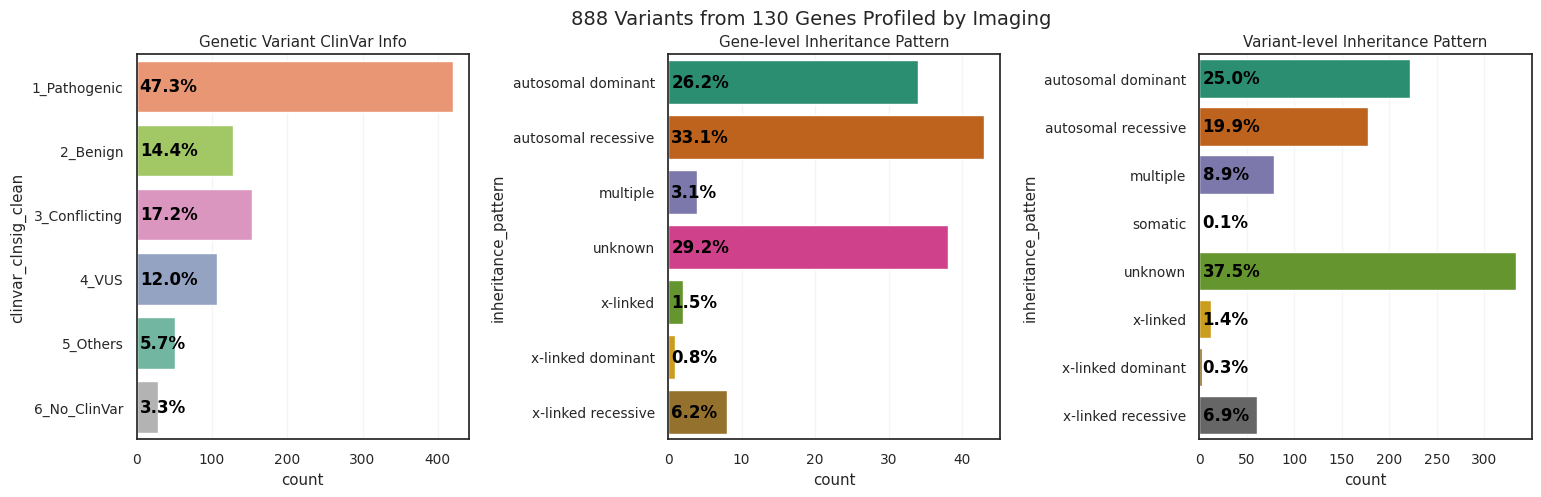

In [14]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
plot_cat_count_perc(
    imaging_summary_clinvar,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
axes[0].set_title("Genetic Variant ClinVar Info")

plot_cat_count_perc(
    imaging_summary_clinvar.unique("symbol"),
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
axes[1].set_title("Gene-level Inheritance Pattern")

plot_cat_count_perc(
    imaging_summary_clinvar,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[2],
)
axes[2].set_title("Variant-level Inheritance Pattern")

plt.suptitle(f"{imaging_summary_clinvar.unique('gene_allele').shape[0]} Variants from {imaging_summary_clinvar.unique('symbol').shape[0]} Genes Profiled by Imaging", y=.97, fontsize=14)
plt.subplots_adjust(wspace=.6)
plt.show()

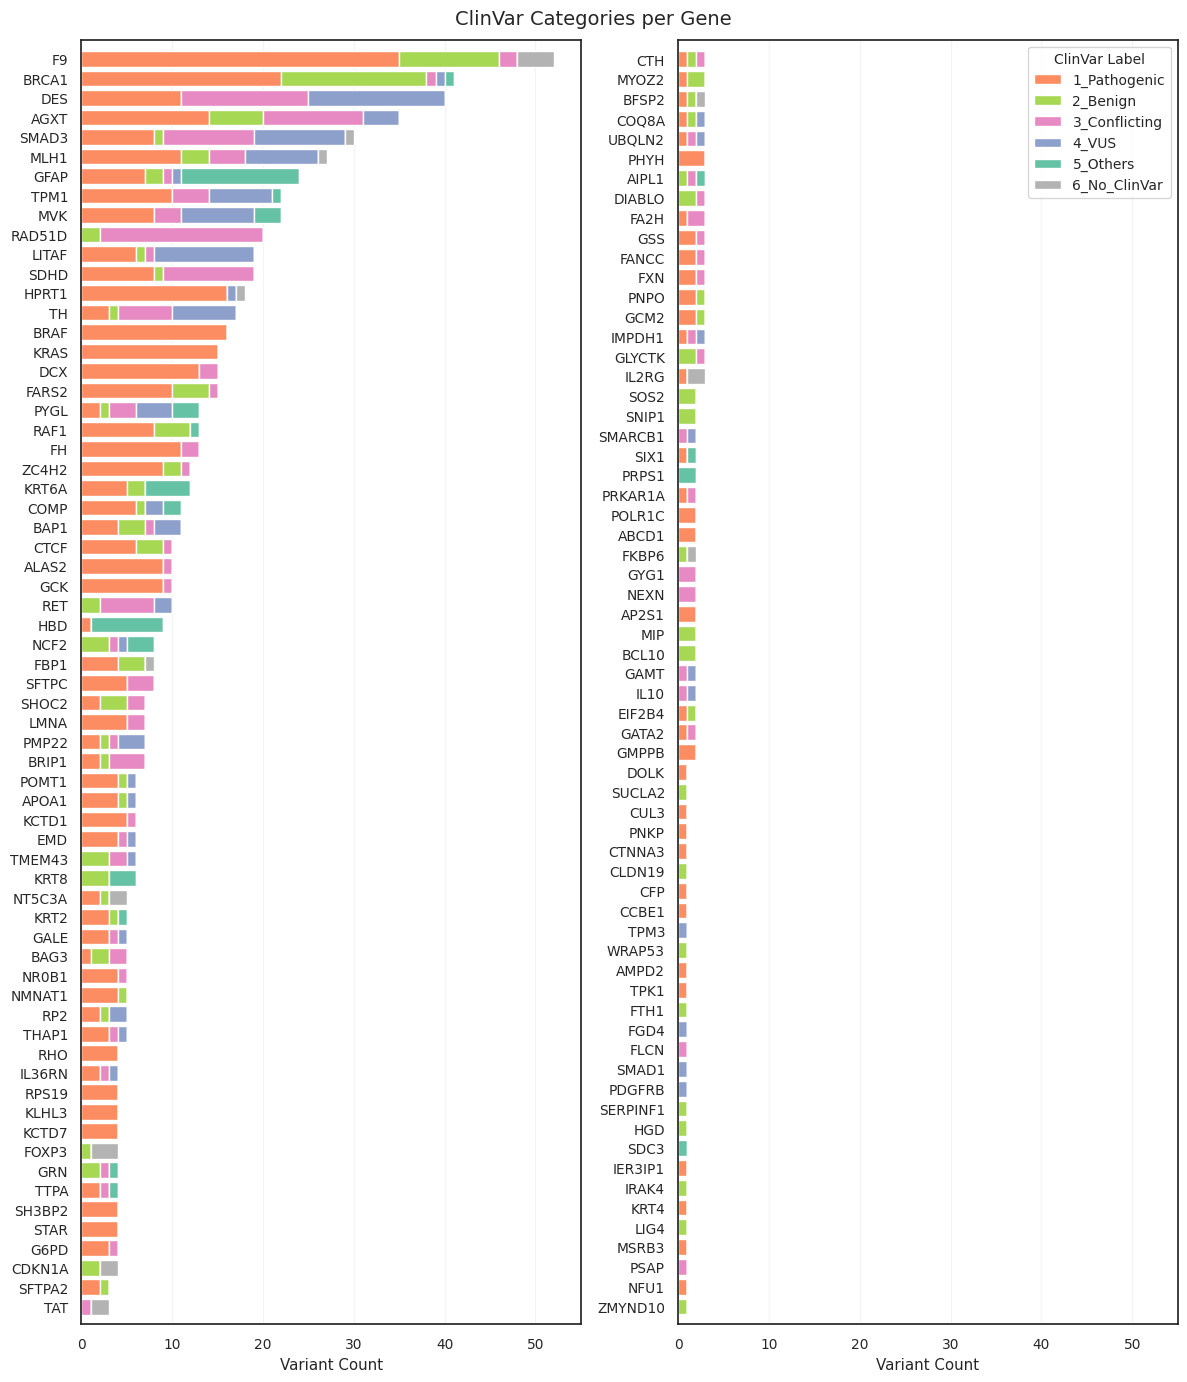

In [15]:
# 2. Count per (gene, category)
df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

top_num = int(np.ceil(imaging_summary_clinvar.unique("symbol").shape[0] / 2))
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# 4. Ensure category order
for cat in category_order:
    if cat not in pivot_top.columns:
        pivot_top[cat] = 0
pivot_top = pivot_top[category_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 55)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in category_order:
    if cat not in pivot_bot.columns:
        pivot_bot[cat] = 0
pivot_bot = pivot_bot[category_order]

bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 55)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.suptitle(f"ClinVar Categories per Gene", fontsize=14, y=.985)
plt.tight_layout()
plt.show()

## 3. Analyses with different categories

<ipython-input-16-e0901ac337f6>:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  xtick_inher = axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=60, ha="right")


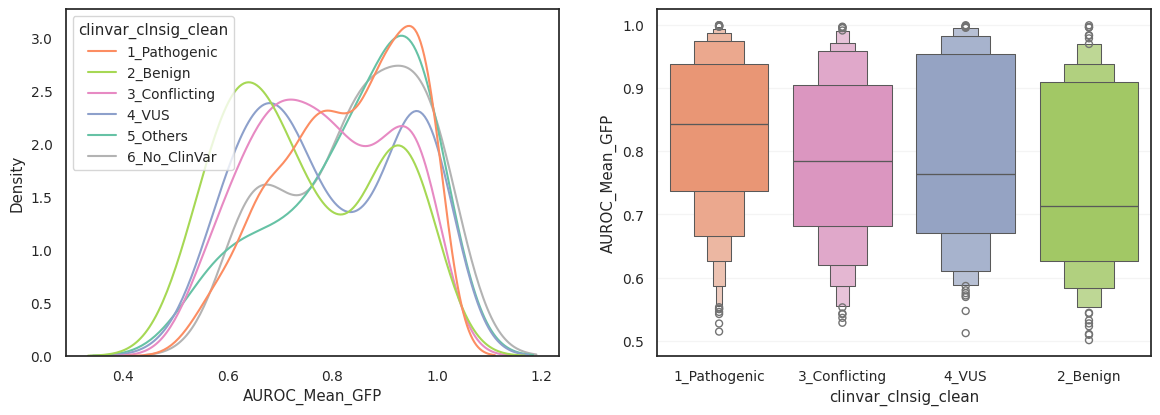

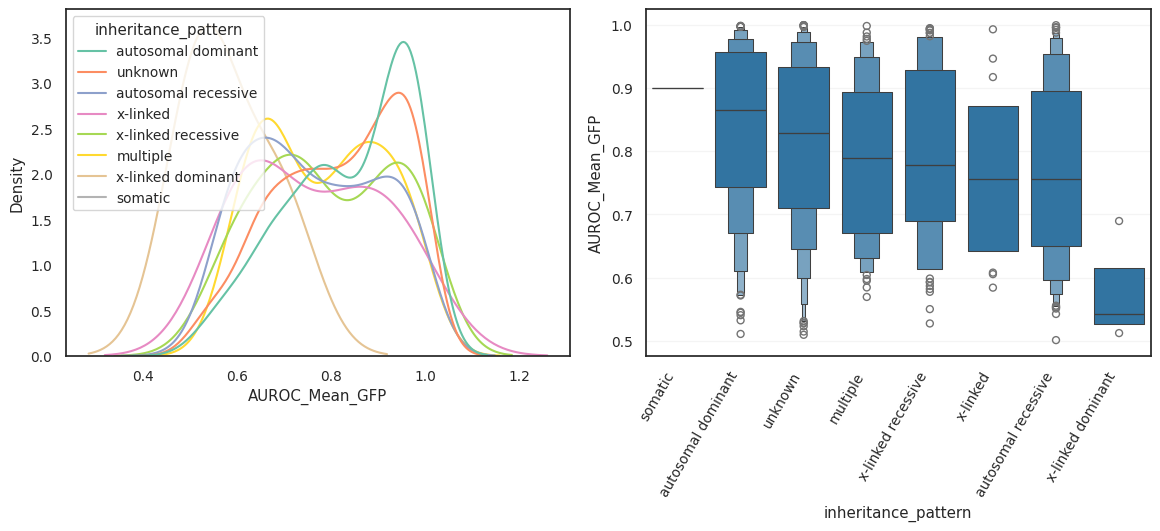

In [16]:
fig, axes = plt.subplots(1,2,figsize=(14, 4.5))
sns.kdeplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="AUROC_Mean_GFP",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"],
    common_norm=False,
    hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
    ax=axes[0]
)
sns.boxenplot(
    data=imaging_summary_clinvar.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])
    ).to_pandas(),
    y="AUROC_Mean_GFP",
    x="clinvar_clnsig_clean",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"],
    order=imaging_summary_clinvar.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])
    ).group_by(
        "clinvar_clnsig_clean"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("clinvar_median")
    ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"],
    # hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
    ax=axes[1]
)
axes[1].grid(alpha=.2, axis="y")
# xtick_inher = axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=60, ha="right")

fig, axes = plt.subplots(1,2,figsize=(14, 4.5))
sns.kdeplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="AUROC_Mean_GFP",
    hue="inheritance_pattern",
    palette="Set2",
    common_norm=False,
    ax=axes[0],
    warn_singular=False
)
axes[1].grid(alpha=.2)
sns.boxenplot(
    data=imaging_summary_clinvar.to_pandas(),
    y="AUROC_Mean_GFP",
    x="inheritance_pattern",
    # hue="inheritance_pattern",
    # palette="Dark2",
    order=imaging_summary_clinvar.group_by(
        "inheritance_pattern"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("inher_median")
    ).sort("inher_median", descending=True)["inheritance_pattern"],
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[1],
)

xtick_inher = axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=60, ha="right")
axes[1].grid(alpha=.2, axis="y")
plt.subplots_adjust(wspace=.15)
plt.show()

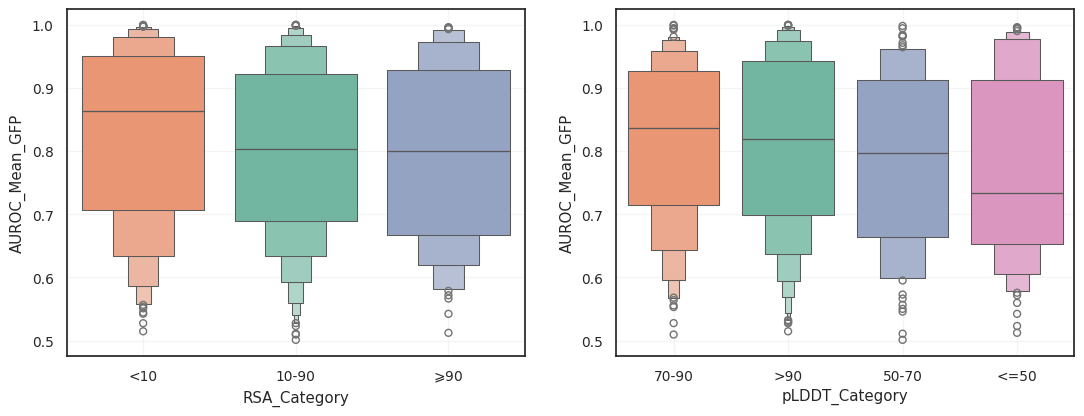

In [17]:
fig, axes = plt.subplots(1,2,figsize=(13, 4.5))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="RSA_Category",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[0]
# )
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="pLDDT_Category",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[1]
# )

sns.boxenplot(
    data=imaging_summary_clinvar.drop_nulls("RSA_Category").to_pandas(),
    y="AUROC_Mean_GFP",
    x="RSA_Category",
    hue="RSA_Category",
    palette="Set2",
    # common_norm=False,
    order=imaging_summary_clinvar.drop_nulls("RSA_Category").group_by(
        "RSA_Category"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("inher_median")
    ).sort("inher_median", descending=True)["RSA_Category"],
    ax=axes[0]
)
sns.boxenplot(
    data=imaging_summary_clinvar.drop_nulls("pLDDT_Category").to_pandas(),
    y="AUROC_Mean_GFP",
    x="pLDDT_Category",
    hue="pLDDT_Category",
    palette="Set2",
    order=imaging_summary_clinvar.drop_nulls("pLDDT_Category").group_by(
        "pLDDT_Category"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("inher_median")
    ).sort("inher_median", descending=True)["pLDDT_Category"],
    # common_norm=False,
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[1]
)

axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
plt.show()

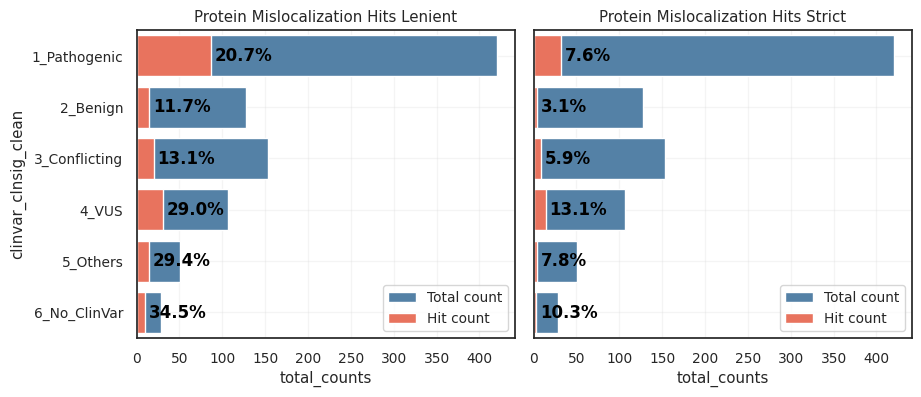

In [18]:
img_metric_df = imaging_summary_clinvar.with_columns(
    (pl.col(GFP_MISLOCAL_FEAT_STRICT)==1).alias("img_prot_hits_5perc_strict"),
    (pl.col(GFP_MISLOCAL_FEAT_LENIENT)==1).alias("img_prot_hits_5perc")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
)

fig, axes = plt.subplots(1,2,figsize=(10,4),sharey=True)
plot_assay_hit_by_category(img_metric_df, "img_prot_hits_5perc", "clinvar_clnsig_clean", f"Protein Mislocalization Hits Lenient", ax=axes[0])
plot_assay_hit_by_category(img_metric_df, "img_prot_hits_5perc_strict", "clinvar_clnsig_clean", f"Protein Mislocalization Hits Strict", ax=axes[1])
plt.subplots_adjust(wspace=.05)
plt.show()

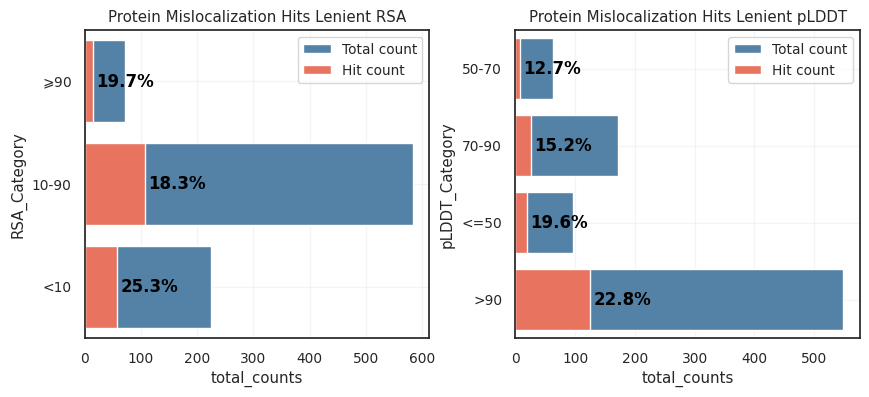

In [19]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
plot_assay_hit_by_category(img_metric_df.drop_nulls("RSA_Category"), "img_prot_hits_5perc", "RSA_Category", f"Protein Mislocalization Hits Lenient RSA", ax=axes[0])
plot_assay_hit_by_category(img_metric_df.drop_nulls("pLDDT_Category"), "img_prot_hits_5perc", "pLDDT_Category", f"Protein Mislocalization Hits Lenient pLDDT", ax=axes[1])
plt.subplots_adjust(wspace=.25)
plt.show()

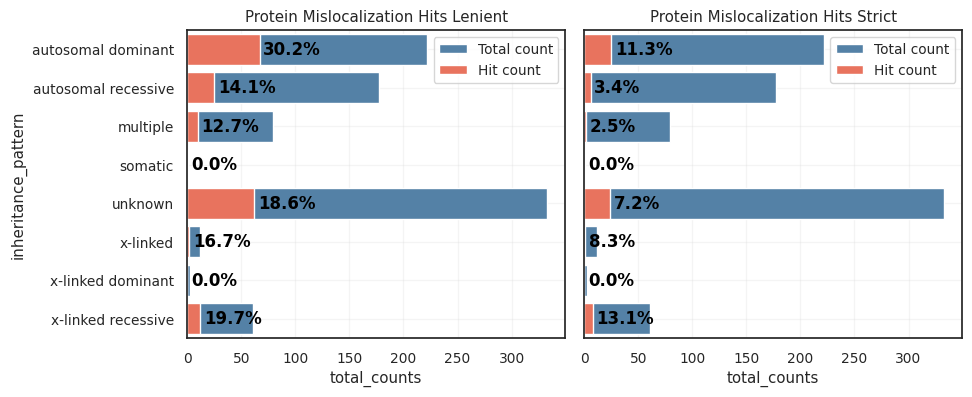

In [20]:
fig, axes = plt.subplots(1,2,figsize=(10,4), sharey=True)
plot_assay_hit_by_category(img_metric_df.drop_nulls("inheritance_pattern"), "img_prot_hits_5perc", "inheritance_pattern", f"Protein Mislocalization Hits Lenient", ax=axes[0])
plot_assay_hit_by_category(img_metric_df.drop_nulls("inheritance_pattern"), "img_prot_hits_5perc_strict", "inheritance_pattern", f"Protein Mislocalization Hits Strict", ax=axes[1])
plt.subplots_adjust(wspace=.05)
plt.show()

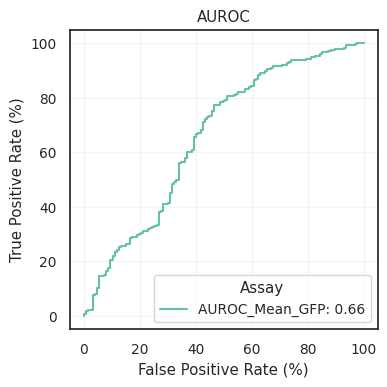

In [21]:
ap_results_dict = plot_auroc_curves(imaging_summary_clinvar, "1_Pathogenic", 
                                    methods=["AUROC_Mean_GFP"])

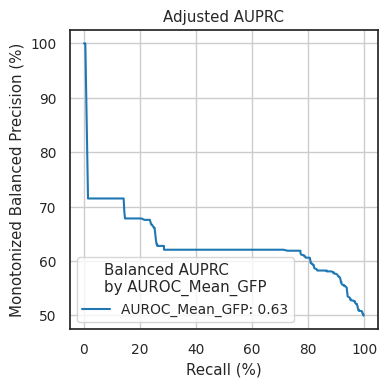

In [22]:
sys.path.insert(1, "../../../../4_compare_ai_scores/2_analysis/scripts")
from yogiroc import *

def plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label, methods, monotonized_flag=True, balanced_flag=True, subsample=False, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    assert (balanced_flag and not subsample) or (subsample and not balanced_flag) or (not subsample and not balanced_flag)
    
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean") == pos_label)
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=["clinvar_clnsig_clean", met])

        if pos_label == "2_Benign":
            df_clin_per_method = df_clin_per_method.with_columns(
                (
                    pl.col(met).neg()
                ).alias(met)
            )
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        if subsample:
            # Assume df is your existing DataFrame with a column named "label"
            # Find the minimum count among the two classes (0 and 1)
            min_count = df_pd['clinvar_label'].value_counts().min()
            # Group by the 'label' column and sample min_count rows from each group (without replacement)
            df_pd = df_pd.groupby('clinvar_label').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)

        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]

        # Create the YogiROC2 object using the new YogiROC2() constructor.
        yrobj = YogiROC2(truth, scores, names=[met], high=True)
        # Get the performance table from the YogiROC2 object.
        table = yrobj.tables[met]

        if (monotonized_flag and balanced_flag):
            table = table.dropna()
        precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
        recall = table["tpr_sens"].values
        # print(precision)
        # print(recall)
        ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
        ap_results[met] = {"AUPRC": ap}

        # Plot the adjusted PR curve.
        axes[m_idx].plot(100 * recall, 100 * precision,
                        label=f"{met}: {ap:.2f}")
        # Plot chance level as a horizontal dashed line.
        prior = np.sum(truth) / df_pd.shape[0]
        if (not balanced_flag):
            axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
        # Customize the subplot.
        handles, labels = axes[methods.index(met)].get_legend_handles_labels()
        precision_label = "Precision (%)"
        title = f"AUPRC\nby {met}"
        
        if balanced_flag:
            precision_label = "Balanced " + precision_label
            title = "Balanced " + title
        if monotonized_flag:
            precision_label = "Monotonized " + precision_label
    
        axes[m_idx].legend(
                        loc="lower left",
                        title=title)
        axes[m_idx].set_xlabel("Recall (%)")
        axes[m_idx].set_ylabel(precision_label)
        axes[m_idx].set_title("Adjusted AUPRC")
        axes[m_idx].grid()

    # sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return None ## , sig_results_dict

plot_adjusted_pr_curves(imaging_summary_clinvar, "1_Pathogenic", 
                        methods=["AUROC_Mean_GFP"])

## 4. Gene-level Analyses

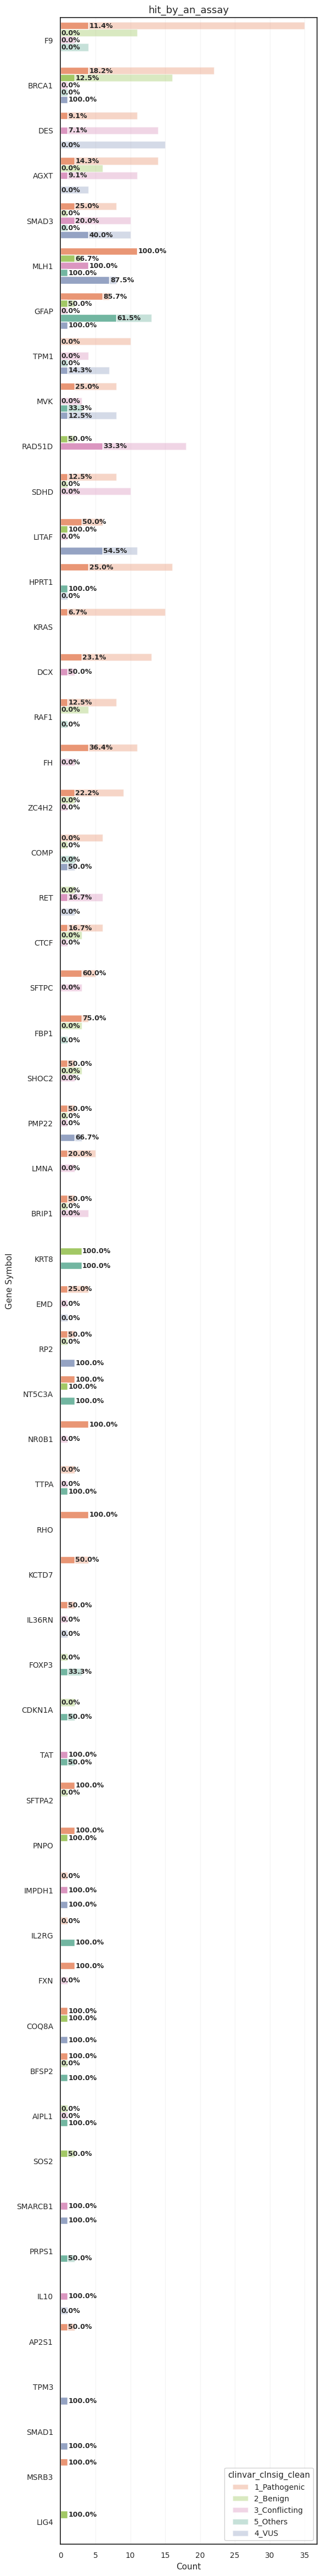

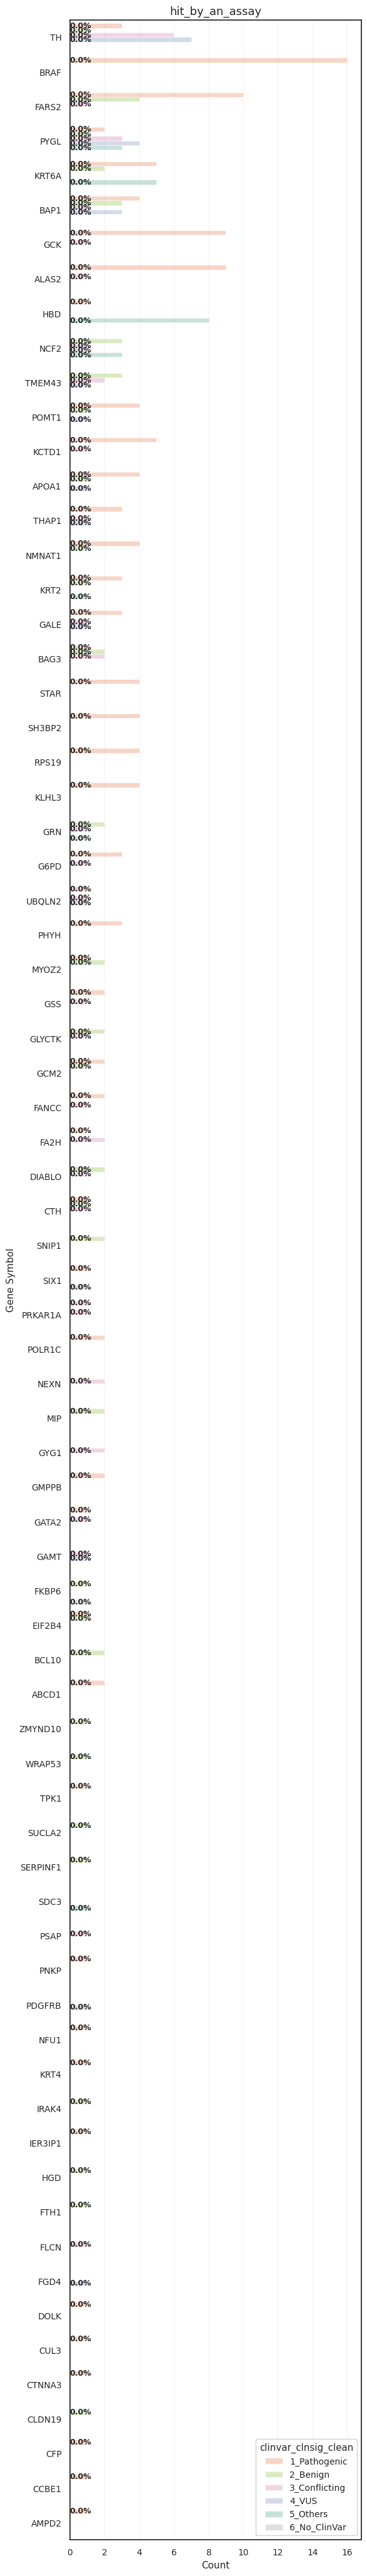

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,TH,1_Pathogenic,3,0,0.0,17
1,TH,2_Benign,1,0,0.0,17
2,TH,3_Conflicting,6,0,0.0,17
3,TH,4_VUS,7,0,0.0,17
4,BRAF,1_Pathogenic,16,0,0.0,16
...,...,...,...,...,...,...
124,CTNNA3,1_Pathogenic,1,0,0.0,1
125,CLDN19,2_Benign,1,0,0.0,1
126,CFP,1_Pathogenic,1,0,0.0,1
127,CCBE1,1_Pathogenic,1,0,0.0,1


In [24]:
plot_gene_level_summary(
    imaging_summary_clinvar.with_columns(
        (
            (pl.col("Altered_95th_perc_both_batches_GFP"))
        ).alias("hit_by_an_assay"),
        pl.col("clinvar_clnsig_clean").replace("6_No_ClinVar", "5_Others")
    ).filter(
        pl.col("Gene").is_in(imaging_summary_clinvar_hits["Gene"].unique())
    ),
    assay="hit_by_an_assay", 
    cat="clinvar_clnsig_clean", 
    palette=palette_dict["clinvar_clnsig_clean"]
)

plot_gene_level_summary(
    imaging_summary_clinvar.with_columns(
        (
            (pl.col("Altered_95th_perc_both_batches_GFP"))
        ).alias("hit_by_an_assay")
    ).filter(
        ~pl.col("Gene").is_in(imaging_summary_clinvar_hits["Gene"].unique())
    ),
    assay="hit_by_an_assay", 
    cat="clinvar_clnsig_clean", 
    palette=palette_dict["clinvar_clnsig_clean"]
)